Mounted at /content/drive
HOUSING DATA
      price  area  bedrooms  bathrooms  stories mainroad guestroom basement  \
0  13300000  7420         4          2        3      yes        no       no   
1  12250000  8960         4          4        4      yes        no       no   
2  12250000  9960         3          2        2      yes        no      yes   
3  12215000  7500         4          2        2      yes        no      yes   
4  11410000  7420         4          1        2      yes       yes      yes   

  hotwaterheating airconditioning  parking prefarea furnishingstatus  
0              no             yes        2      yes        furnished  
1              no             yes        3       no        furnished  
2              no              no        2      yes   semi-furnished  
3              no             yes        3      yes        furnished  
4              no             yes        2       no        furnished  

Missing values:
price               0
area                0

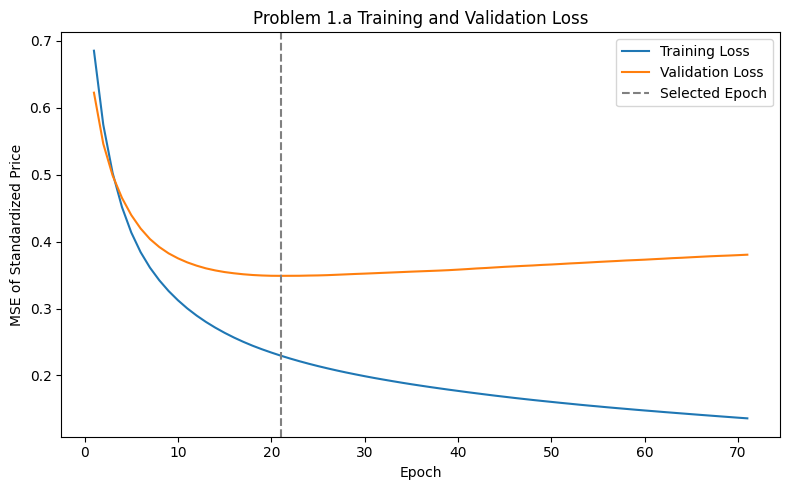


PROBLEM 1.A TEST RESULTS
                         Model          MSE         RMSE  R-Squared
Fully Connected Neural Network 1.844383e+12 1.358081e+06   0.635106

Selected SVR parameters: {'C': 1, 'epsilon': 0.05, 'gamma': 0.01}

PROBLEM 1.B TEST COMPARISON
                         Model          MSE         RMSE  R-Squared
Fully Connected Neural Network 1.844383e+12 1.358081e+06   0.635106
             Linear Regression 1.754319e+12 1.324507e+06   0.652924
     Support Vector Regression 1.943805e+12 1.394204e+06   0.615436

Lowest test MSE: Linear Regression

BREAST CANCER DATA
         id diagnosis  radius_mean  texture_mean  perimeter_mean  area_mean  \
0    842302         M        17.99         10.38          122.80     1001.0   
1    842517         M        20.57         17.77          132.90     1326.0   
2  84300903         M        19.69         21.25          130.00     1203.0   
3  84348301         M        11.42         20.38           77.58      386.1   
4  84358402        

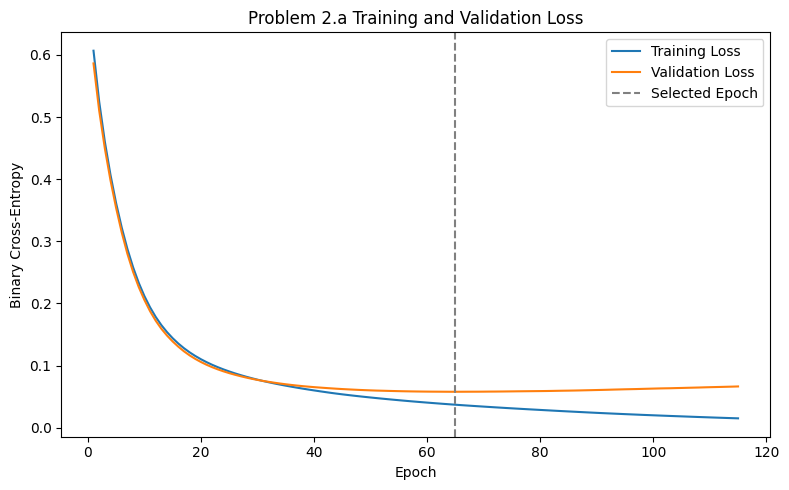

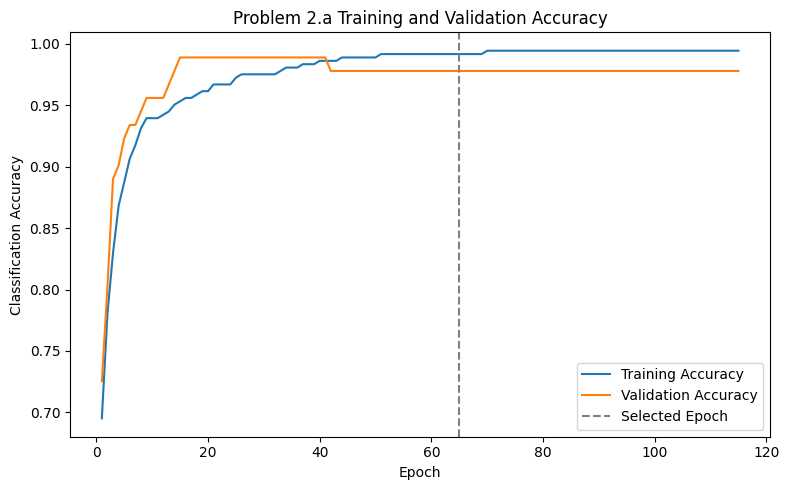


PROBLEM 2.A TEST RESULTS
                         Model  Accuracy  Precision   Recall  F1 Score
Fully Connected Neural Network  0.973684        1.0 0.928571  0.962963


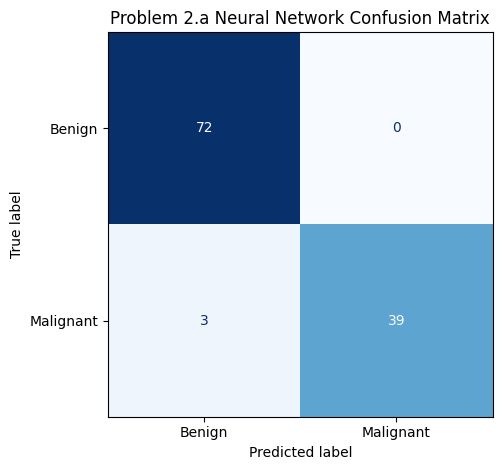


Selected Logistic Regression C: 0.1
Selected SVM parameters: {'C': 0.1, 'gamma': 0.1}

PROBLEM 2.B TEST COMPARISON
                         Model  Accuracy  Precision   Recall  F1 Score
Fully Connected Neural Network  0.973684   1.000000 0.928571  0.962963
           Logistic Regression  0.982456   1.000000 0.952381  0.975610
        Support Vector Machine  0.894737   0.857143 0.857143  0.857143

Highest test F1 score: Logistic Regression


In [ ]:
# Homework 6
# Gabriel Almodovar
# Student ID: 801296062

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPRegressor, MLPClassifier
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.svm import SVR, SVC

from sklearn.metrics import (
    mean_squared_error,
    r2_score,
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    ConfusionMatrixDisplay
)

np.random.seed(42)


# LOAD DATA FROM GOOGLE DRIVE

try:
    from google.colab import drive
    drive.mount('/content/drive')

    dataset_path = (
        '/content/drive/My Drive/Courses/Intro-to-ML/Datasets'
    )

except ImportError:
    dataset_path = 'upload'

housing_path = os.path.join(dataset_path, 'Housing.csv')
cancer_path = os.path.join(dataset_path, 'Cancer.csv')


# FUNCTIONS USED THROUGHOUT THE HOMEWORK

def create_network(problem_type, hidden_layers, learning_rate):

    if problem_type == 'regression':

        model = MLPRegressor(
            hidden_layer_sizes=hidden_layers,
            activation='relu',
            solver='adam',
            learning_rate_init=learning_rate,
            alpha=0.01,
            batch_size=32,
            shuffle=True,
            random_state=42
        )

    else:

        model = MLPClassifier(
            hidden_layer_sizes=hidden_layers,
            activation='relu',
            solver='adam',
            learning_rate_init=learning_rate,
            alpha=0.01,
            batch_size=32,
            shuffle=True,
            random_state=42
        )

    return model


def train_network(
    X_train, Y_train,
    X_validation, Y_validation,
    problem_type, hidden_layers, learning_rate
):

    model = create_network(
        problem_type, hidden_layers, learning_rate
    )

    train_loss = []
    validation_loss = []
    train_accuracy = []
    validation_accuracy = []

    best_validation_loss = np.inf
    best_epoch = 0

    max_epochs = 500
    patience = 50

    for epoch in range(max_epochs):

        # PARTIAL_FIT TRAINS THE NETWORK FOR ONE EPOCH
        if problem_type == 'regression':

            model.partial_fit(X_train, Y_train)

            prediction_train = model.predict(X_train)
            prediction_validation = model.predict(X_validation)

            training_loss = mean_squared_error(
                Y_train, prediction_train
            )

            current_validation_loss = mean_squared_error(
                Y_validation, prediction_validation
            )

        else:

            model.partial_fit(
                X_train, Y_train,
                classes=np.array([0, 1])
            )

            probability_train = model.predict_proba(X_train)
            probability_validation = model.predict_proba(
                X_validation
            )

            training_loss = log_loss(
                Y_train, probability_train,
                labels=[0, 1]
            )

            current_validation_loss = log_loss(
                Y_validation, probability_validation,
                labels=[0, 1]
            )

            train_accuracy.append(
                accuracy_score(
                    Y_train, model.predict(X_train)
                )
            )

            validation_accuracy.append(
                accuracy_score(
                    Y_validation, model.predict(X_validation)
                )
            )

        train_loss.append(training_loss)
        validation_loss.append(current_validation_loss)

        # SELECT THE BEST EPOCH USING VALIDATION LOSS
        if current_validation_loss < best_validation_loss - 1e-8:

            best_validation_loss = current_validation_loss
            best_epoch = epoch + 1

        # STOP AFTER 50 EPOCHS WITHOUT VALIDATION IMPROVEMENT
        if epoch + 1 - best_epoch >= patience:
            break

    return {
        'Hidden Layers': hidden_layers,
        'Learning Rate': learning_rate,
        'Best Epoch': best_epoch,
        'Validation Loss': best_validation_loss,
        'Training Loss History': train_loss,
        'Validation Loss History': validation_loss,
        'Training Accuracy History': train_accuracy,
        'Validation Accuracy History': validation_accuracy
    }


def select_network(
    X_train, Y_train,
    X_validation, Y_validation,
    problem_type
):

    experiments = []

    for hidden_layers in [(32, 16), (64, 32)]:

        for learning_rate in [0.001, 0.0003]:

            result = train_network(
                X_train, Y_train,
                X_validation, Y_validation,
                problem_type, hidden_layers, learning_rate
            )

            experiments.append(result)

    best_result = experiments[0]

    for result in experiments:

        if result['Validation Loss'] < best_result['Validation Loss']:
            best_result = result

    experiment_table = pd.DataFrame([
        {
            'Hidden Layers': result['Hidden Layers'],
            'Learning Rate': result['Learning Rate'],
            'Best Epoch': result['Best Epoch'],
            'Validation Loss': result['Validation Loss']
        }
        for result in experiments
    ])

    return best_result, experiment_table


def refit_network(X_train, Y_train, problem_type, best_result):

    model = create_network(
        problem_type,
        best_result['Hidden Layers'],
        best_result['Learning Rate']
    )

    # USE THE SELECTED EPOCH COUNT ON THE FULL TRAINING SET
    for epoch in range(best_result['Best Epoch']):

        if problem_type == 'regression':
            model.partial_fit(X_train, Y_train)

        else:
            model.partial_fit(
                X_train, Y_train,
                classes=np.array([0, 1])
            )

    return model


def regression_metrics(model_name, Y_actual, Y_prediction):

    mse = mean_squared_error(Y_actual, Y_prediction)

    return {
        'Model': model_name,
        'MSE': mse,
        'RMSE': np.sqrt(mse),
        'R-Squared': r2_score(Y_actual, Y_prediction)
    }


def classification_metrics(model_name, Y_actual, Y_prediction):

    return {
        'Model': model_name,
        'Accuracy': accuracy_score(Y_actual, Y_prediction),
        'Precision': precision_score(
            Y_actual, Y_prediction, zero_division=0
        ),
        'Recall': recall_score(
            Y_actual, Y_prediction, zero_division=0
        ),
        'F1 Score': f1_score(
            Y_actual, Y_prediction, zero_division=0
        )
    }


# PROBLEM 1.A
# PREPARE THE HOUSING DATA

Housing = pd.read_csv(housing_path)

print("HOUSING DATA")
print(Housing.head())

print("\nMissing values:")
print(Housing.isnull().sum())

yes_no_columns = [
    'mainroad', 'guestroom', 'basement',
    'hotwaterheating', 'airconditioning', 'prefarea'
]

Housing[yes_no_columns] = Housing[yes_no_columns].apply(
    lambda column: column.map({'yes': 1, 'no': 0})
)

# FIXED CATEGORIES DO NOT REQUIRE LEARNING FROM THE TEST DATA
Housing['furnishingstatus'] = pd.Categorical(
    Housing['furnishingstatus'],
    categories=['furnished', 'semi-furnished', 'unfurnished']
)

Housing = pd.get_dummies(
    Housing,
    columns=['furnishingstatus'],
    drop_first=True,
    dtype=int
)

X_housing = Housing.drop(columns=['price']).to_numpy(dtype=float)
Y_housing = Housing['price'].to_numpy(dtype=float)

assert np.isfinite(X_housing).all()
assert np.isfinite(Y_housing).all()

print("\nHousing input features:", X_housing.shape[1])


# SPLIT INTO 80% TRAINING AND 20% TEST DATA

(
    X_train_housing, X_test_housing,
    Y_train_housing, Y_test_housing
) = train_test_split(
    X_housing, Y_housing,
    test_size=0.20,
    random_state=42
)

# VALIDATION DATA COME FROM THE TRAINING SET ONLY
(
    X_fit_housing, X_validation_housing,
    Y_fit_housing, Y_validation_housing
) = train_test_split(
    X_train_housing, Y_train_housing,
    test_size=0.20,
    random_state=42
)

print("Training pool:", len(Y_train_housing))
print("Training subset:", len(Y_fit_housing))
print("Validation subset:", len(Y_validation_housing))
print("Test samples:", len(Y_test_housing))


# STANDARDIZE USING THE TRAINING SUBSET ONLY

input_scaler_housing = StandardScaler()

X_fit_housing_scaled = input_scaler_housing.fit_transform(
    X_fit_housing
)

X_validation_housing_scaled = input_scaler_housing.transform(
    X_validation_housing
)

# SCALE PRICES TO KEEP NETWORK TRAINING STABLE
price_scaler = StandardScaler()

Y_fit_housing_scaled = price_scaler.fit_transform(
    Y_fit_housing.reshape(-1, 1)
).ravel()

Y_validation_housing_scaled = price_scaler.transform(
    Y_validation_housing.reshape(-1, 1)
).ravel()


# TRAIN THE HOUSING NEURAL NETWORK

best_housing, housing_experiments = select_network(
    X_fit_housing_scaled,
    Y_fit_housing_scaled,
    X_validation_housing_scaled,
    Y_validation_housing_scaled,
    problem_type='regression'
)

print("\nHOUSING NEURAL NETWORK EXPERIMENTS")
print(housing_experiments.to_string(index=False))

print("\nSelected hidden layers:", best_housing['Hidden Layers'])
print("Selected learning rate:", best_housing['Learning Rate'])
print("Selected epochs:", best_housing['Best Epoch'])


# PLOT TRAINING AND VALIDATION LOSS

epochs_housing = np.arange(
    1, len(best_housing['Training Loss History']) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_housing,
    best_housing['Training Loss History'],
    label="Training Loss"
)

plt.plot(
    epochs_housing,
    best_housing['Validation Loss History'],
    label="Validation Loss"
)

plt.axvline(
    best_housing['Best Epoch'],
    color='gray',
    linestyle='--',
    label="Selected Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("MSE of Standardized Price")
plt.title("Problem 1.a Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()


# REFIT USING THE FULL 80% TRAINING SET
# REFIT SCALERS AFTER HYPERPARAMETER SELECTION

final_input_scaler_housing = StandardScaler()

X_train_housing_scaled = (
    final_input_scaler_housing.fit_transform(X_train_housing)
)

X_test_housing_scaled = (
    final_input_scaler_housing.transform(X_test_housing)
)

final_price_scaler = StandardScaler()

Y_train_housing_scaled = final_price_scaler.fit_transform(
    Y_train_housing.reshape(-1, 1)
).ravel()

housing_network = refit_network(
    X_train_housing_scaled,
    Y_train_housing_scaled,
    'regression',
    best_housing
)

prediction_network_scaled = housing_network.predict(
    X_test_housing_scaled
)

# RETURN PREDICTIONS TO THE ORIGINAL PRICE UNITS
prediction_housing_network = final_price_scaler.inverse_transform(
    prediction_network_scaled.reshape(-1, 1)
).ravel()

housing_network_results = regression_metrics(
    'Fully Connected Neural Network',
    Y_test_housing,
    prediction_housing_network
)

print("\nPROBLEM 1.A TEST RESULTS")
print(pd.DataFrame([housing_network_results]).to_string(index=False))


# PROBLEM 1.B
# LINEAR REGRESSION

linear_model = LinearRegression()

linear_model.fit(
    X_train_housing_scaled,
    Y_train_housing_scaled
)

prediction_linear_scaled = linear_model.predict(
    X_test_housing_scaled
)

prediction_linear = final_price_scaler.inverse_transform(
    prediction_linear_scaled.reshape(-1, 1)
).ravel()


# SELECT SVR PARAMETERS USING VALIDATION DATA ONLY

best_svr_loss = np.inf
best_svr_parameters = None

for C in [0.1, 1, 10, 100]:

    for epsilon in [0.05, 0.1, 0.2]:

        for gamma in ['scale', 0.01, 0.1]:

            svr_model = SVR(
                kernel='rbf',
                C=C,
                epsilon=epsilon,
                gamma=gamma
            )

            svr_model.fit(
                X_fit_housing_scaled,
                Y_fit_housing_scaled
            )

            prediction_validation = svr_model.predict(
                X_validation_housing_scaled
            )

            validation_mse = mean_squared_error(
                Y_validation_housing_scaled,
                prediction_validation
            )

            if validation_mse < best_svr_loss:

                best_svr_loss = validation_mse

                best_svr_parameters = {
                    'C': C,
                    'epsilon': epsilon,
                    'gamma': gamma
                }

print("\nSelected SVR parameters:", best_svr_parameters)


# REFIT SVR USING THE FULL TRAINING SET

svr_model = SVR(
    kernel='rbf',
    **best_svr_parameters
)

svr_model.fit(
    X_train_housing_scaled,
    Y_train_housing_scaled
)

prediction_svr_scaled = svr_model.predict(
    X_test_housing_scaled
)

prediction_svr = final_price_scaler.inverse_transform(
    prediction_svr_scaled.reshape(-1, 1)
).ravel()


# COMPARE ALL THREE REGRESSION MODELS

comparison_1b = pd.DataFrame([
    housing_network_results,

    regression_metrics(
        'Linear Regression',
        Y_test_housing,
        prediction_linear
    ),

    regression_metrics(
        'Support Vector Regression',
        Y_test_housing,
        prediction_svr
    )
])

print("\nPROBLEM 1.B TEST COMPARISON")
print(comparison_1b.to_string(index=False))

best_regression_model = comparison_1b.loc[
    comparison_1b['MSE'].idxmin(), 'Model'
]

print("\nLowest test MSE:", best_regression_model)


# PROBLEM 2.A
# PREPARE THE BREAST CANCER DATA

Cancer = pd.read_csv(cancer_path)

print("\nBREAST CANCER DATA")
print(Cancer.head())

# REMOVE THE IDENTIFIER AND EMPTY COLUMN
Cancer = Cancer.drop(
    columns=['id', 'Unnamed: 32'],
    errors='ignore'
)

# BENIGN = 0, MALIGNANT = 1
Cancer['diagnosis'] = Cancer['diagnosis'].map({
    'B': 0,
    'M': 1
})

print("\nMissing values:")
print(Cancer.isnull().sum())

X_cancer = Cancer.drop(columns=['diagnosis']).to_numpy(dtype=float)
Y_cancer = Cancer['diagnosis'].to_numpy(dtype=int)

assert X_cancer.shape[1] == 30
assert np.isfinite(X_cancer).all()
assert set(Y_cancer) == {0, 1}

print("\nCancer input features:", X_cancer.shape[1])


# SPLIT INTO 80% TRAINING AND 20% TEST DATA

(
    X_train_cancer, X_test_cancer,
    Y_train_cancer, Y_test_cancer
) = train_test_split(
    X_cancer, Y_cancer,
    test_size=0.20,
    random_state=42,
    stratify=Y_cancer
)

# PRESERVE CLASS PROPORTIONS IN THE VALIDATION SPLIT
(
    X_fit_cancer, X_validation_cancer,
    Y_fit_cancer, Y_validation_cancer
) = train_test_split(
    X_train_cancer, Y_train_cancer,
    test_size=0.20,
    random_state=42,
    stratify=Y_train_cancer
)

print("Training pool:", len(Y_train_cancer))
print("Training subset:", len(Y_fit_cancer))
print("Validation subset:", len(Y_validation_cancer))
print("Test samples:", len(Y_test_cancer))


# STANDARDIZE USING THE TRAINING SUBSET ONLY

input_scaler_cancer = StandardScaler()

X_fit_cancer_scaled = input_scaler_cancer.fit_transform(
    X_fit_cancer
)

X_validation_cancer_scaled = input_scaler_cancer.transform(
    X_validation_cancer
)


# TRAIN THE CLASSIFICATION NEURAL NETWORK

best_cancer, cancer_experiments = select_network(
    X_fit_cancer_scaled,
    Y_fit_cancer,
    X_validation_cancer_scaled,
    Y_validation_cancer,
    problem_type='classification'
)

print("\nCANCER NEURAL NETWORK EXPERIMENTS")
print(cancer_experiments.to_string(index=False))

print("\nSelected hidden layers:", best_cancer['Hidden Layers'])
print("Selected learning rate:", best_cancer['Learning Rate'])
print("Selected epochs:", best_cancer['Best Epoch'])


# PLOT TRAINING AND VALIDATION LOSS

epochs_cancer = np.arange(
    1, len(best_cancer['Training Loss History']) + 1
)

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_cancer,
    best_cancer['Training Loss History'],
    label="Training Loss"
)

plt.plot(
    epochs_cancer,
    best_cancer['Validation Loss History'],
    label="Validation Loss"
)

plt.axvline(
    best_cancer['Best Epoch'],
    color='gray',
    linestyle='--',
    label="Selected Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Binary Cross-Entropy")
plt.title("Problem 2.a Training and Validation Loss")
plt.legend()
plt.tight_layout()
plt.show()


# PLOT TRAINING AND VALIDATION ACCURACY

plt.figure(figsize=(8, 5))

plt.plot(
    epochs_cancer,
    best_cancer['Training Accuracy History'],
    label="Training Accuracy"
)

plt.plot(
    epochs_cancer,
    best_cancer['Validation Accuracy History'],
    label="Validation Accuracy"
)

plt.axvline(
    best_cancer['Best Epoch'],
    color='gray',
    linestyle='--',
    label="Selected Epoch"
)

plt.xlabel("Epoch")
plt.ylabel("Classification Accuracy")
plt.title("Problem 2.a Training and Validation Accuracy")
plt.legend()
plt.tight_layout()
plt.show()


# REFIT USING THE FULL 80% TRAINING SET

final_input_scaler_cancer = StandardScaler()

X_train_cancer_scaled = (
    final_input_scaler_cancer.fit_transform(X_train_cancer)
)

X_test_cancer_scaled = (
    final_input_scaler_cancer.transform(X_test_cancer)
)

cancer_network = refit_network(
    X_train_cancer_scaled,
    Y_train_cancer,
    'classification',
    best_cancer
)

# PROBABILITY OF AT LEAST 0.5 IS CLASSIFIED AS MALIGNANT
probability_cancer = cancer_network.predict_proba(
    X_test_cancer_scaled
)[:, 1]

prediction_cancer_network = (
    probability_cancer >= 0.5
).astype(int)

cancer_network_results = classification_metrics(
    'Fully Connected Neural Network',
    Y_test_cancer,
    prediction_cancer_network
)

print("\nPROBLEM 2.A TEST RESULTS")
print(pd.DataFrame([cancer_network_results]).to_string(index=False))


# PLOT THE NEURAL NETWORK CONFUSION MATRIX

cancer_confusion = confusion_matrix(
    Y_test_cancer,
    prediction_cancer_network,
    labels=[0, 1]
)

confusion_display = ConfusionMatrixDisplay(
    confusion_matrix=cancer_confusion,
    display_labels=['Benign', 'Malignant']
)

confusion_display.plot(cmap='Blues', colorbar=False)

plt.title("Problem 2.a Neural Network Confusion Matrix")
plt.tight_layout()
plt.show()


# PROBLEM 2.B
# SELECT LOGISTIC REGRESSION USING VALIDATION F1

best_logistic_f1 = -1
best_logistic_C = None

for C in [0.01, 0.1, 1, 10]:

    logistic_model = LogisticRegression(
        C=C,
        max_iter=5000,
        random_state=42
    )

    logistic_model.fit(
        X_fit_cancer_scaled,
        Y_fit_cancer
    )

    prediction_validation = logistic_model.predict(
        X_validation_cancer_scaled
    )

    validation_f1 = f1_score(
        Y_validation_cancer,
        prediction_validation,
        zero_division=0
    )

    if validation_f1 > best_logistic_f1:

        best_logistic_f1 = validation_f1
        best_logistic_C = C

print("\nSelected Logistic Regression C:", best_logistic_C)


# REFIT LOGISTIC REGRESSION USING THE FULL TRAINING SET

logistic_model = LogisticRegression(
    C=best_logistic_C,
    max_iter=5000,
    random_state=42
)

logistic_model.fit(
    X_train_cancer_scaled,
    Y_train_cancer
)

prediction_logistic = logistic_model.predict(
    X_test_cancer_scaled
)


# SELECT SVM PARAMETERS USING VALIDATION F1

best_svm_f1 = -1
best_svm_parameters = None

for C in [0.1, 1, 10]:

    for gamma in ['scale', 0.01, 0.1]:

        svm_model = SVC(
            kernel='rbf',
            C=C,
            gamma=gamma
        )

        svm_model.fit(
            X_fit_cancer_scaled,
            Y_fit_cancer
        )

        prediction_validation = svm_model.predict(
            X_validation_cancer_scaled
        )

        validation_f1 = f1_score(
            Y_validation_cancer,
            prediction_validation,
            zero_division=0
        )

        if validation_f1 > best_svm_f1:

            best_svm_f1 = validation_f1

            best_svm_parameters = {
                'C': C,
                'gamma': gamma
            }

print("Selected SVM parameters:", best_svm_parameters)


# REFIT SVM USING THE FULL TRAINING SET

svm_model = SVC(
    kernel='rbf',
    **best_svm_parameters
)

svm_model.fit(
    X_train_cancer_scaled,
    Y_train_cancer
)

prediction_svm = svm_model.predict(
    X_test_cancer_scaled
)


# COMPARE ALL THREE CLASSIFICATION MODELS

comparison_2b = pd.DataFrame([
    cancer_network_results,

    classification_metrics(
        'Logistic Regression',
        Y_test_cancer,
        prediction_logistic
    ),

    classification_metrics(
        'Support Vector Machine',
        Y_test_cancer,
        prediction_svm
    )
])

print("\nPROBLEM 2.B TEST COMPARISON")
print(comparison_2b.to_string(index=False))

best_classification_model = comparison_2b.loc[
    comparison_2b['F1 Score'].idxmax(), 'Model'
]

print("\nHighest test F1 score:", best_classification_model)